# visualize results (segmentation mask)
- same as 22 a but for ICON data
- input: segmentation output (mask) (in this case: from interactive nbook 25)
- output: map of segmentation results, global and fro subregion

In [1]:
# set date
date ="2023-06-06-1800"#  "2023-06-06-1800"


param_tag = "anvil_detectthres225_seg241_cell_detectthres10_seg10"

inputpath =  f"../output/apply_seg/apply_ICON_with_mask_from_nbook/combi_mask/mask_combi_{param_tag}_{date}.nc"


### somehow tb need to be loaded here otherwise hdf error

In [2]:
# load tools
import sys 
sys.path.append("../tools")
import handle_ICON_data as ic
import plots_mapping
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns


import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

# load data

In [3]:
# data selection
zoom = 9

vlist = ["pr", "rlut", "tas", "qsvi","clivi","qgvi","crs"]

# load data
dataset = ic.open_ngc4008(zoom = zoom) 

# select timestamp and variables
dataset = ic.select_time(dataset, date)
dataset = ic.select_vars(dataset, vlist)

# calculate input variables 
dataset = ic.add_input_vars(dataset)
dataset


# resample to Imerg grid
tb = ic.resample_to_lon_lat(dataset, "tb_11", zoom = zoom, to_imerg = True)
precip= ic.resample_to_lon_lat(dataset ,"rain_tot_rate", zoom = zoom ,to_imerg = True)

precip.attrs["short_name"]=  "Rain rate"
precip.attrs["units"] = r"mm h$^{-1}$"

tb.attrs["short_name"]  = "BT"



## import package 

In [4]:
from defs_application import georegions

In [5]:
import xarray as xr
import pandas as pd
from pathlib import Path
import seaborn as sns


In [6]:
# diir where to save plots
plot_dir=Path("../output/plots")
if not plot_dir.is_dir():
    plot_dir.mkdir()

## Load data

In [7]:
# load detection
# load segmentation mask
segmentation_mask  = xr.open_dataset(inputpath,engine="h5netcdf")
# convert to xarray

#convert to xarray
seg2d_cell_filtered  = segmentation_mask["segmentation_mask_cell_filtered"].squeeze()
seg2d_anvil_filtered = segmentation_mask["segmentation_mask_anvil_filtered"].squeeze()

# all
seg2d_cell  = segmentation_mask["segmentation_mask_cell"].squeeze()
seg2d_anvil = segmentation_mask["segmentation_mask_anvil"].squeeze()



# bg layer where all pixels that represent a deselected cell are assigned same value=> so they appear the same grey
seg2d_anvil_bg = seg2d_anvil.where(seg2d_anvil == 0, other=1)
seg2d_cell_bg = seg2d_cell.where(seg2d_cell== 0, other=1)
#seg2d_cell_bg

# cretae colormaps ONCE
cmap_anvil, norm_anvil = plots_mapping.build_id_cmap([seg2d_anvil, seg2d_anvil_filtered], seed=0)
cmap_cell,  norm_cell  = plots_mapping.build_id_cmap([seg2d_cell,  seg2d_cell_filtered],  seed=1)

date_title = plots_mapping.title_time_format(segmentation_mask)

threshold_anvil = int(seg2d_anvil.attrs["threshold"])
unit_threshold_anvil = "K"


threshold_cell = float(seg2d_cell.attrs["threshold"])
unit_threshold_cell = "mm/h"




# plot of limited domain

# global plot

# domain plot with underlying image of segmentation


# main plots
## quickplot anvil

## Quick plot precip 

# combined plot

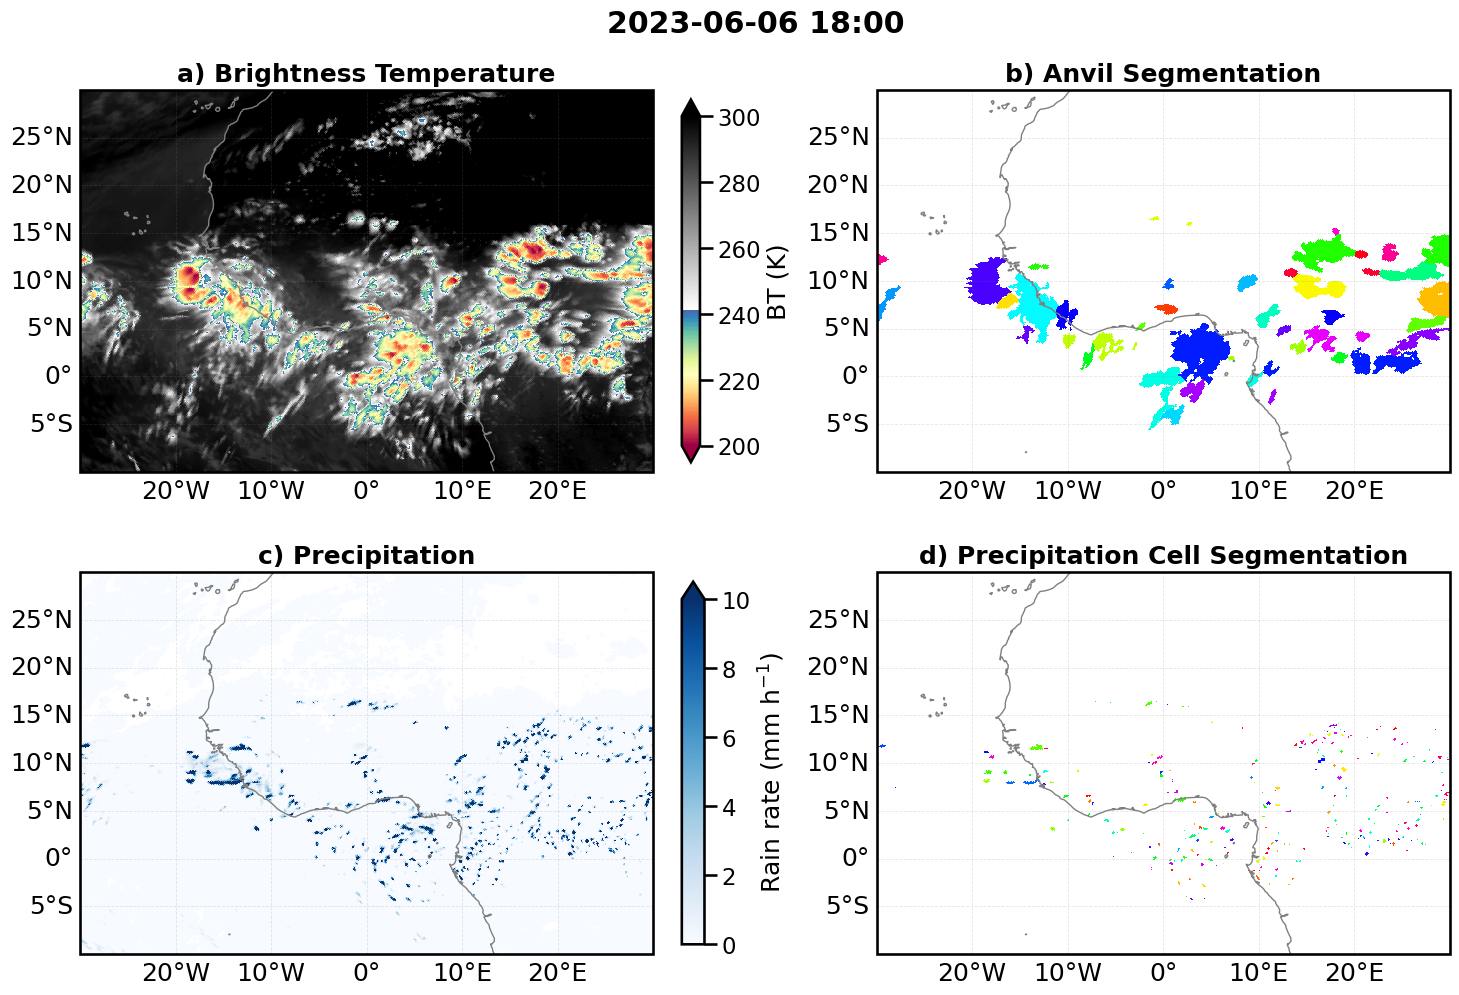

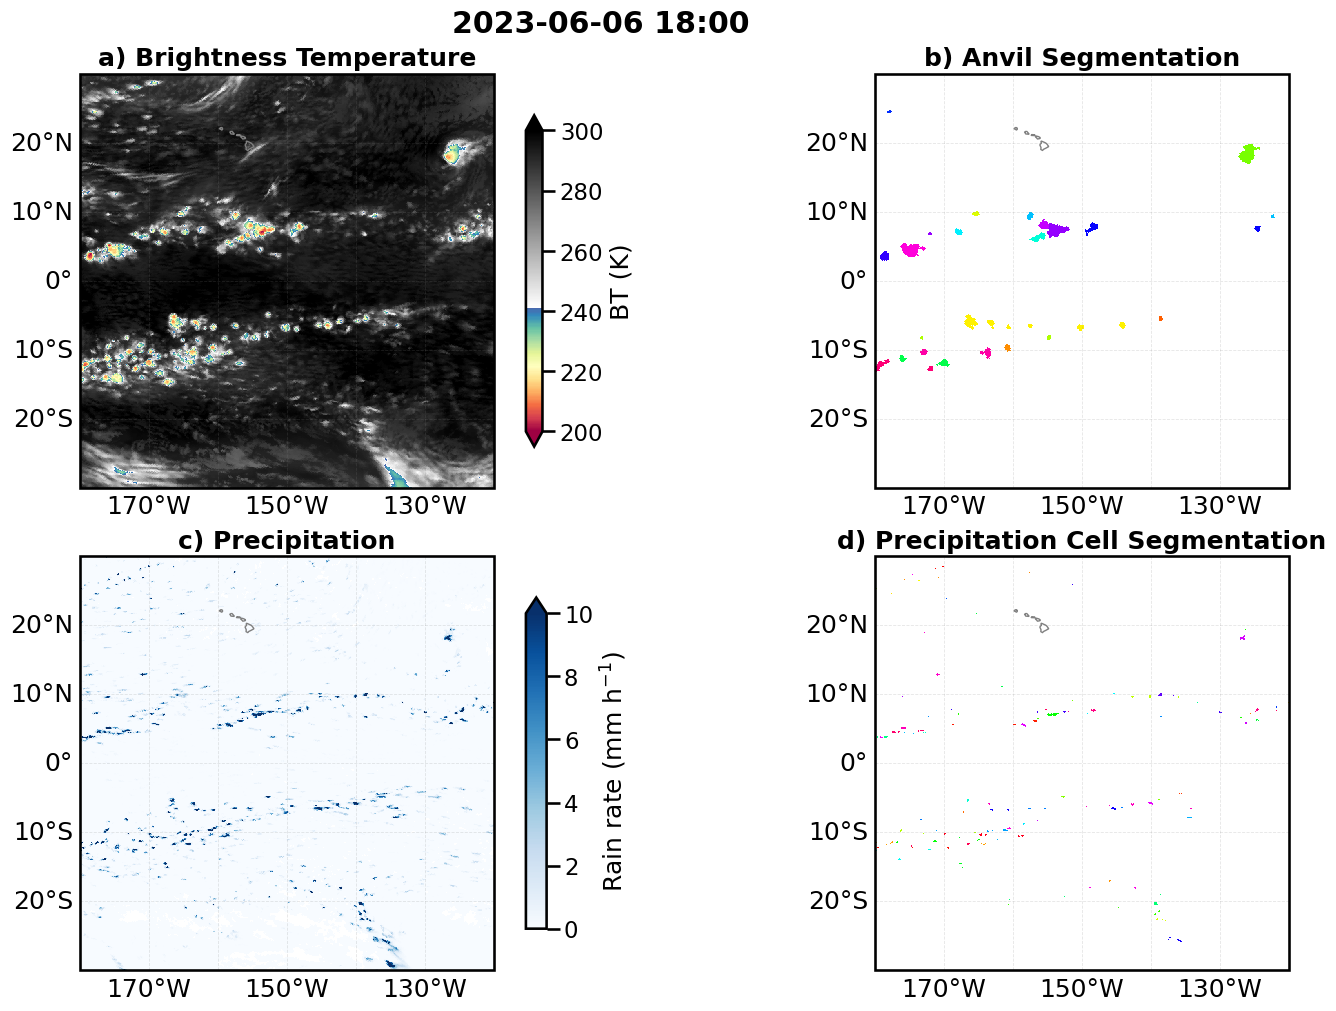

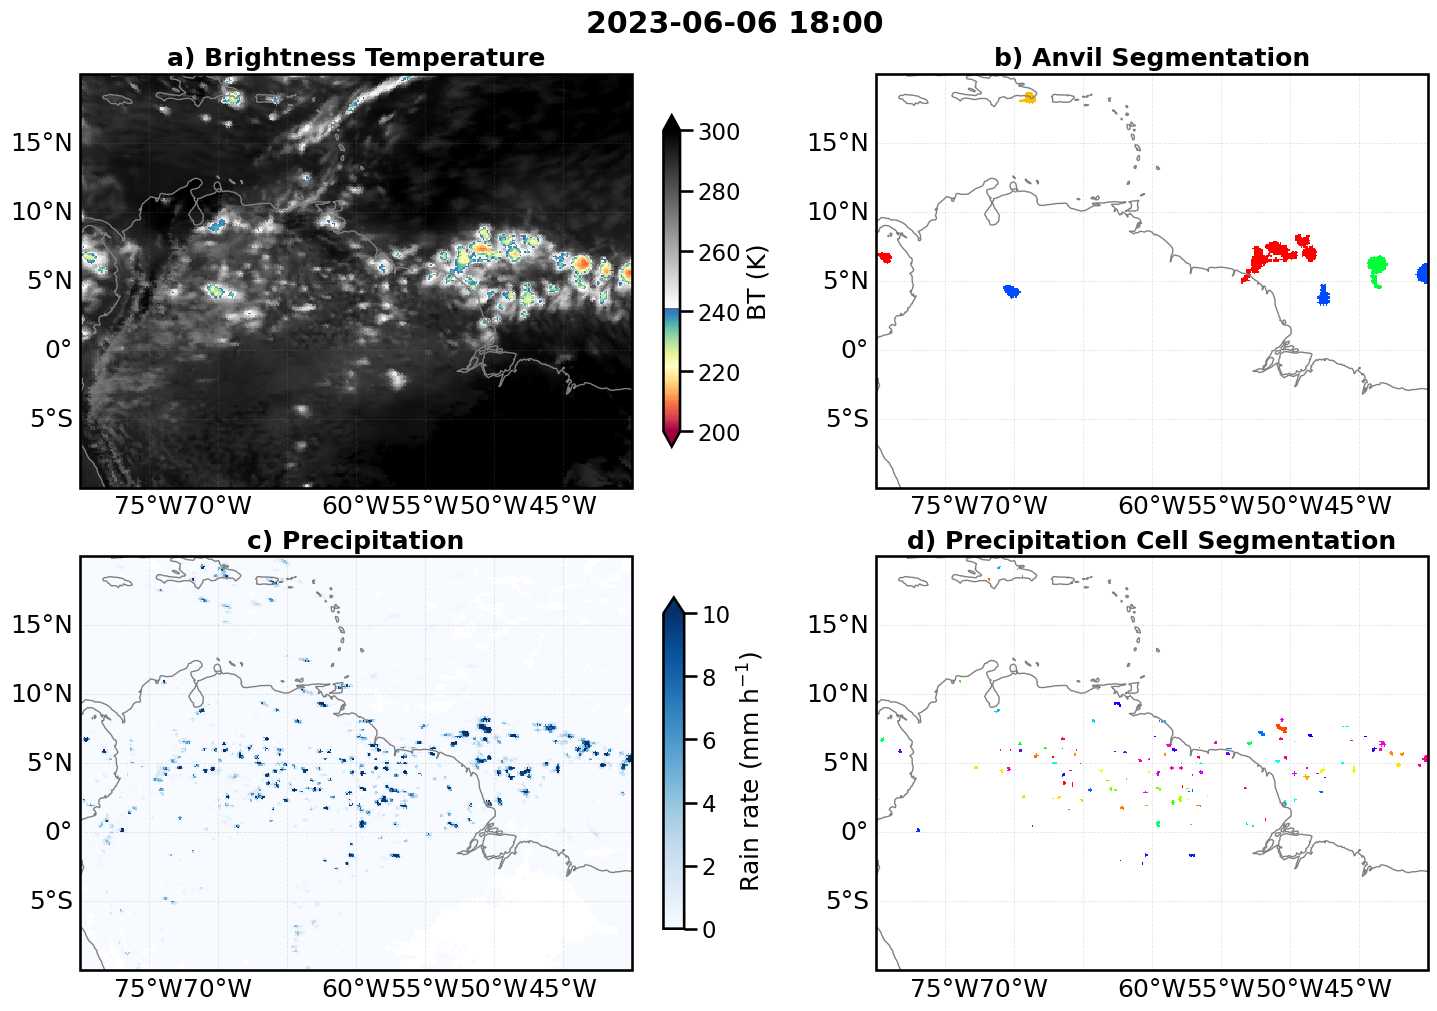

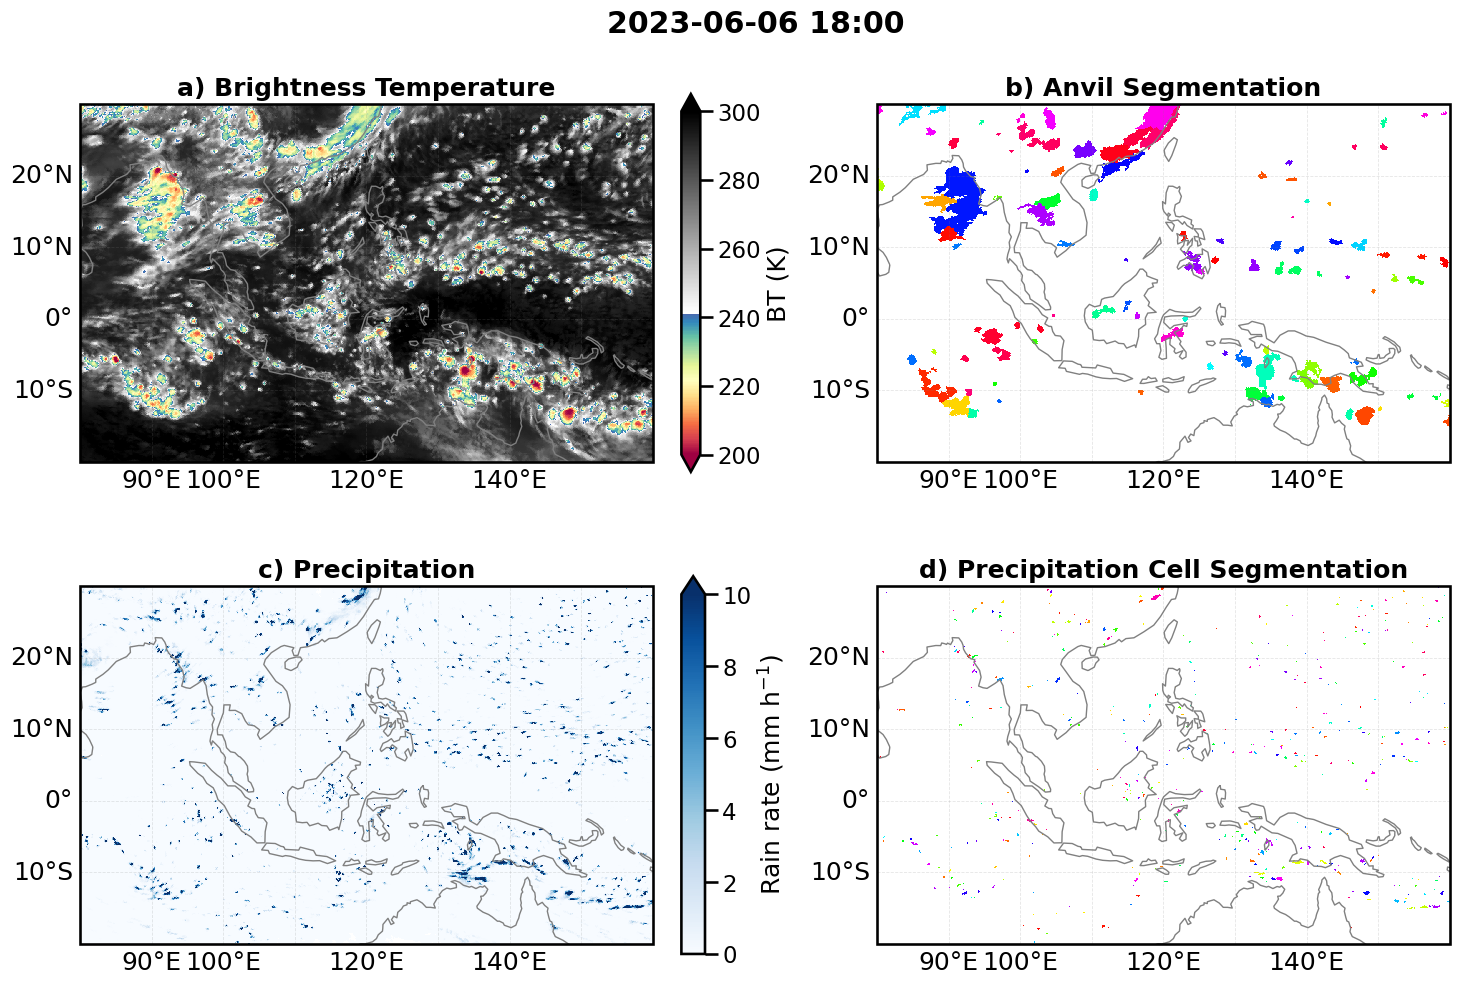

In [8]:
sns.set_context("talk")
#plt.style.use('tex')

# def georegion 
#georegion = "africa_0"

for georegion in georegions.keys():
    if georegion == "global":
        continue

    # plot
    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout = True
    )
    
    # tb image
    fig, axes[0, 0], _ = plots_mapping.domain_plot_tb(tb, domain=georegions[georegion], title="a) Brightness Temperature", fig=fig, ax=axes[0, 0])
    # anvil seg
    fig, axes[0, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil, domain=georegions[georegion], title="b) Anvil Segmentation", fig=fig, ax=axes[0, 1])
    # precip image
    fig, axes[1, 0], _ = plots_mapping.domain_plot_precip(precip,vmin = 0, vmax = 10, domain=georegions[georegion], title="c) Precipitation", fig=fig, ax=axes[1, 0])
    # precip seg
    fig, axes[1, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_cell, domain=georegions[georegion], title="d) Precipitation Cell Segmentation", fig=fig, ax=axes[1, 1])
    
    fig.suptitle(f"{date_title}", fontweight="bold")
    
    # solve unequal subplot soizes due to colorbar
    # reserve colorbar space for segmentation plot
    dummy = plt.cm.ScalarMappable(cmap="Greys")
    cbar = fig.colorbar(dummy, ax=axes[0, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    
    #plt.tight_layout()
    
    #fig.savefig(os.path.join(plot_dir,f"quickplot_segmentation_ICON_combined_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')
    
    plt.show()
    

# one global plot

# combi plot with filered anvils 


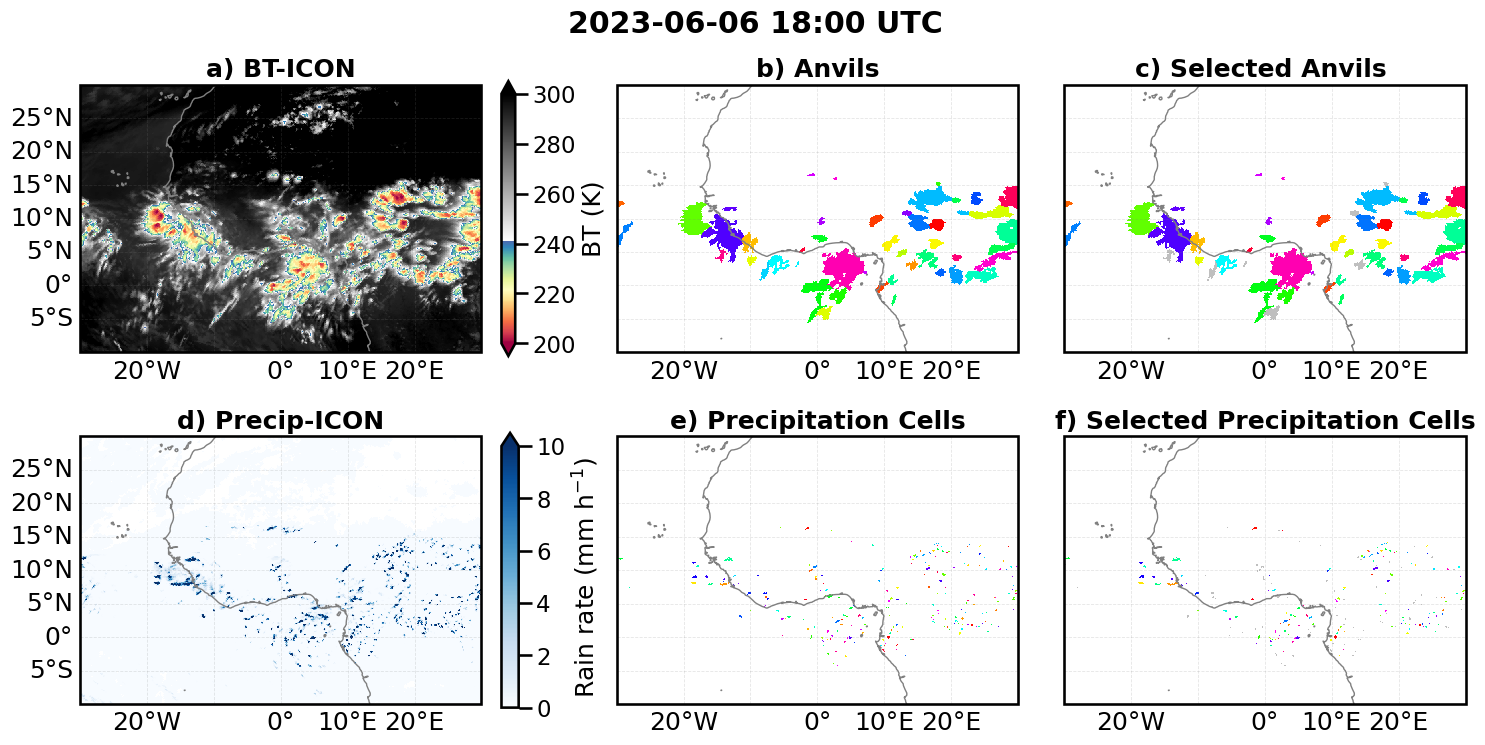

In [9]:
from matplotlib.colors import ListedColormap

bg_cmap = ListedColormap([
    (1, 1, 1, 0.0),   # 0 → fully transparent
    (0.75, 0.75, 0.75, 1.0)  # 1 → light grey (darker than before)
])

sns.set_context("talk")
#plt.style.use('tex')

# def georegion 
georegion = ["africa_0"]

for georegion in georegion: #georegions.keys(): #
    if georegion == "global":
        continue

    lon_min, lon_max, lat_min, lat_max = georegions[georegion]
    lon_extent = lon_max - lon_min
    lat_extent = lat_max - lat_min

    fig_width = 15
    # account for ~10% width lost to colorbars on col 0
    effective_lon = lon_extent * 0.90
    fig_height = fig_width * (lat_extent / effective_lon) * (2 / 3)
    fig_height = max(5, min(fig_height, 20))

    # plot
    fig, axes = plt.subplots(
        2, 3,
        figsize=(fig_width, fig_height),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout = True
    )
    
    # tb image
    _, axes[0, 0], _ = plots_mapping.domain_plot_tb(tb, domain=georegions[georegion],left_grid_label=True,bottom_grid_label = True, title="a) BT-ICON", fig=fig, ax=axes[0, 0])
    # anvil seg
    _, axes[0, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil, cmap=cmap_anvil,norm = norm_anvil,domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="b) Anvils", fig=fig, ax=axes[0, 1])
    # anvil seg
    _, axes[0, 2], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil, domain=georegions[georegion], left_grid_label=False,bottom_grid_label = True,
                                                            background=seg2d_anvil_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="c) Selected Anvils ", fig=fig, ax=axes[0, 2])

    # precip image
    _, axes[1, 0], _ = plots_mapping.domain_plot_precip(precip,vmin = 0, vmax = 10, domain=georegions[georegion], left_grid_label=True,bottom_grid_label = True,title="d) Precip-ICON", fig=fig, ax=axes[1, 0])
    # precip seg
    _, axes[1, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_cell,cmap=cmap_cell,norm = norm_cell, domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="e) Precipitation Cells", fig=fig, ax=axes[1, 1])
    # precip seg
    _, axes[1, 2], _ = plots_mapping.domain_plot_seg_mask(seg2d_cell_filtered, cmap=cmap_cell,norm = norm_cell,domain=georegions[georegion], left_grid_label=False,bottom_grid_label = True,
                                                            background=seg2d_cell_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="f) Selected Precipitation Cells", fig=fig, ax=axes[1, 2])
    
    fig.suptitle(f"{date_title} UTC", fontweight="bold")
    
    # solve unequal subplot soizes due to colorbar
    dummy = plt.cm.ScalarMappable(cmap="Greys")
    cbar = fig.colorbar(dummy, ax=axes[0, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[0, 2], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 2], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)

    #plt.tight_layout()
    
    fig.savefig(os.path.join(plot_dir,f"quickplot_segmentation_ICON_combined_filtered_cells_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')
   
    fig.canvas.draw()

    plt.show()
    plt.close(fig)
   

# global filtered vs non filtered anvils

# precip and anvil global togther selected with grey 

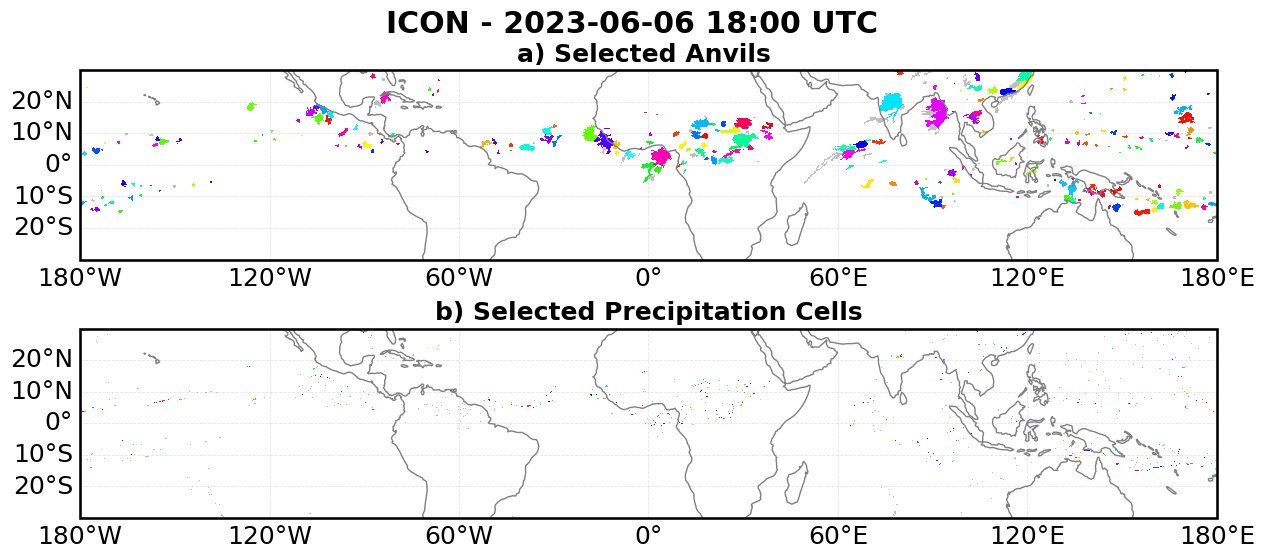

In [16]:
georegion = "global"
#plt.style.use('tex')
sns.set_context("talk")

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

fig,axes[0], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil, domain=georegions[georegion], 
                                                            background=seg2d_anvil_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="a) Selected Anvils ", fig=fig, ax=axes[0])
fig,axes[1], _= plots_mapping.domain_plot_seg_mask(seg2d_cell_filtered, cmap=cmap_cell,norm = norm_cell,domain=georegions[georegion],
                                                            background=seg2d_cell_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="b) Selected Precipitation Cells", fig=fig, ax=axes[1])
    

fig.suptitle(f"ICON - {date_title} UTC", fontweight="bold", y = 0.93)

plt.tight_layout()
plt.show()
fig.savefig(os.path.join(plot_dir,f"quickplot_seg_output_global_ICON_{date}.pdf"),dpi=150, bbox_inches='tight')

# for tobac nan umgang

In [11]:
georegions.keys()

dict_keys(['global', 'africa_0', 'pacific', 'amazonas', 'maritime'])

In [12]:
#georegions
georegions_sel = {'global': [-180, 180, -30, 30],
 #'africa_0': [-30, 30, -10, 30],
 'pacific': [-180, -120, -30, 30],
 #'amazonas': [-80, -40, -10, 20],
 'maritime': [80, 180, -15, 20]}

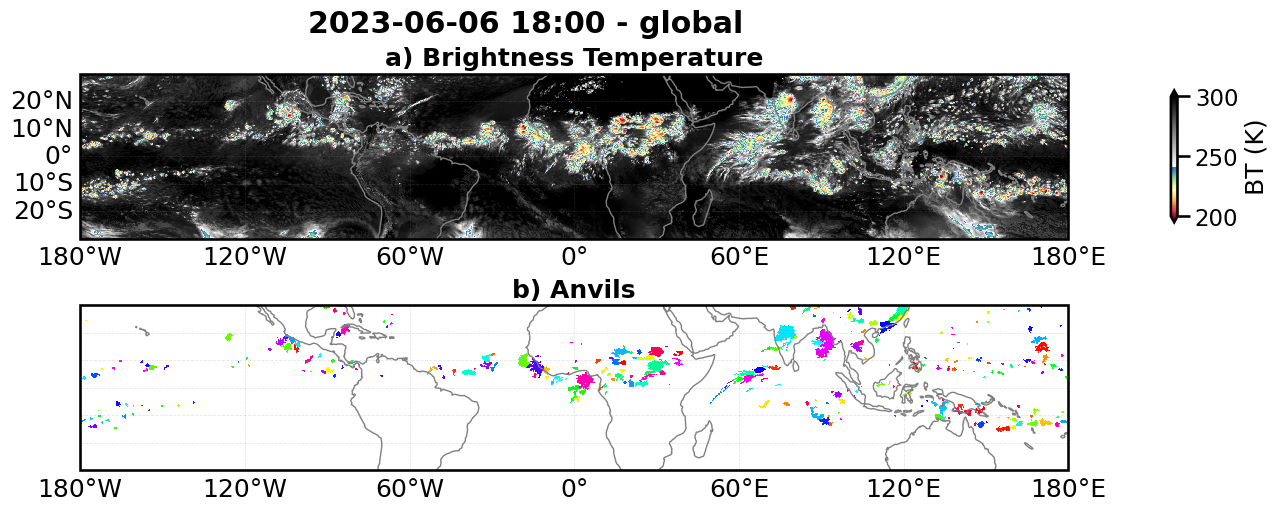

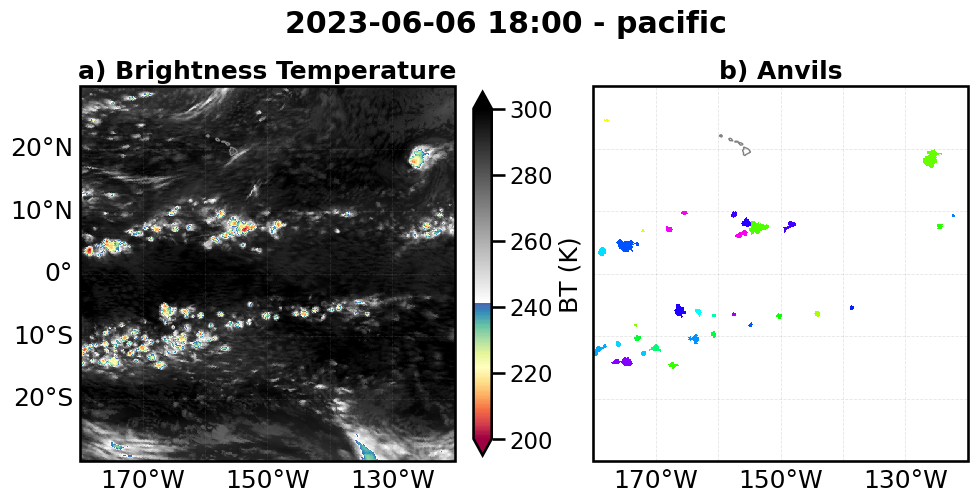

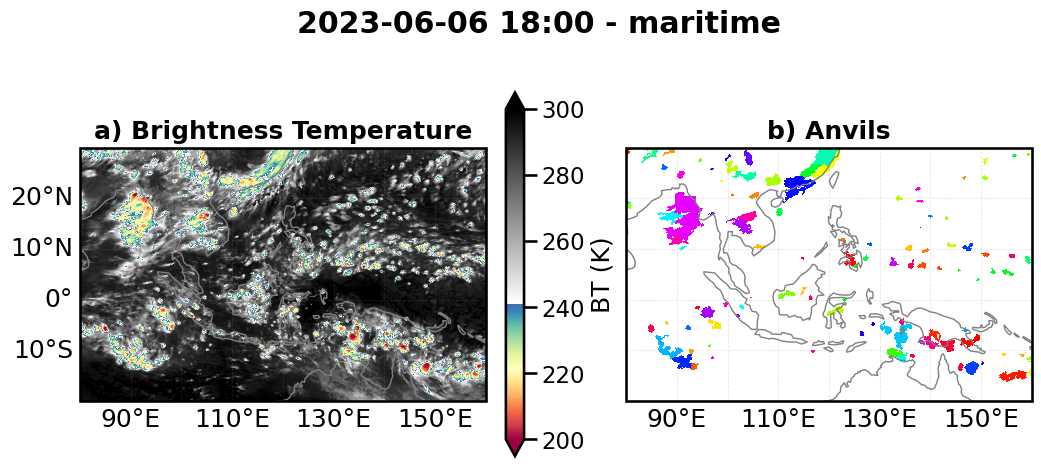

In [13]:
from matplotlib.colors import ListedColormap

bg_cmap = ListedColormap([
    (1, 1, 1, 0.0),   # 0 → fully transparent
    (0.75, 0.75, 0.75, 1.0)  # 1 → light grey (darker than before)
])

sns.set_context("talk")
#plt.style.use('tex')

# def georegion 

for georegion in georegions_sel.keys(): #georegion:
    # if georegion == "global":
    #     continue

    lon_min, lon_max, lat_min, lat_max = georegions[georegion]
    lon_extent = lon_max - lon_min
    lat_extent = lat_max - lat_min



    if georegion == "global":
        fig_width = 15
        # account for ~10% width lost to colorbars on col 0
        effective_lon = lon_extent * 0.90
        fig_height = fig_width * (lat_extent / effective_lon) * (2 / 3)
        fig_height = max(5, min(fig_height, 20))
        # plot
        fig, axes = plt.subplots(
            2, 1,
            figsize=(fig_width, fig_height),
            subplot_kw={"projection": ccrs.PlateCarree()},
            constrained_layout = True
        )
        # tb image
        _, axes[0], _ = plots_mapping.domain_plot_tb(tb, domain=georegions[georegion],left_grid_label=True,bottom_grid_label = True, title="a) Brightness Temperature", fig=fig, ax=axes[0])
        # anvil seg
        _, axes[ 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil, cmap=cmap_anvil,norm = norm_anvil,domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="b) Anvils", fig=fig, ax=axes[1])
    else: 
         # horizontal layout: 1 row, 2 columns
        scale = lon_extent / 360  # normalize vs global longitudinal span
    
        fig_width = min(15, 8+ 12 * scale)  # scalable but capped at 15
    
        effective_lon = lon_extent * 1.8
    
        fig_height = fig_width * (lat_extent / effective_lon) * (2 / 3)
        fig_height = max(5, min(fig_height, 20))
            # plot
        fig, axes = plt.subplots(
            1, 2,
            figsize=(fig_width, fig_height),
            subplot_kw={"projection": ccrs.PlateCarree()},
            constrained_layout = True
        )
        # tb image
        _, axes[0], _ = plots_mapping.domain_plot_tb(tb, domain=georegions[georegion],left_grid_label=True,bottom_grid_label = True, title="a) Brightness Temperature", fig=fig, ax=axes[0])
        # anvil seg
        _, axes[ 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil, cmap=cmap_anvil,norm = norm_anvil,domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="b) Anvils", fig=fig, ax=axes[1])
   
    fig.suptitle(f"{date_title} - {georegion}", fontweight="bold", ha = "center", x=0.5)
    
    # # solve unequal subplot soizes due to colorbar
    dummy = plt.cm.ScalarMappable(cmap="Greys")
    cbar = fig.colorbar(dummy, ax=axes[1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    # cbar = fig.colorbar(dummy, ax=axes[1, 1], fraction=0.046, pad=0.04)
    # cbar.ax.set_visible(False)
    # cbar = fig.colorbar(dummy, ax=axes[0, 2], fraction=0.046, pad=0.04)
    # cbar.ax.set_visible(False)
    # cbar = fig.colorbar(dummy, ax=axes[1, 2], fraction=0.046, pad=0.04)
    # cbar.ax.set_visible(False)

    #plt.tight_layout()
    
    #fig.savefig(os.path.join(plot_dir,f"quickplot_segmentation_ICON_combined_filtered_cells_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')
   
    fig.canvas.draw()

    plt.show()
    plt.close(fig)
   